# SVM for Brain Tumor Detection 

## Imports

In [3]:
import kagglehub
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Download Dataset

In [4]:
path = kagglehub.dataset_download(
    "navoneel/brain-mri-images-for-brain-tumor-detection"
)

print("Dataset Path:", path)

100%|██████████| 15.1M/15.1M [00:25<00:00, 617kB/s]

Extracting files...


Dataset Path: C:\Users\Hannan Mazhar\.cache\kagglehub\datasets\navoneel\brain-mri-images-for-brain-tumor-detection\versions\1


## Load and Preprocess Images

In [5]:
images = []
labels = []

for root, dirs, files in os.walk(path):
    folder = os.path.basename(root).lower()

    if folder not in ["yes", "no"]:
        continue

    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            image_path = os.path.join(root, file)

            image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

            if image is not None:
                image = cv2.resize(image, (64, 64))

                images.append(image)
                labels.append(1 if folder == "yes" else 0)

images = np.array(images)
labels = np.array(labels)

print("\nTotal Images:", len(images))
print("Images Shape:", images.shape)

print("\nTarget Distribution:")
print("No Tumor (0):", np.sum(labels == 0))
print("Tumor (1):", np.sum(labels == 1))

if len(images) == 0:
    raise ValueError(
        "No images found. Check the downloaded dataset folders "
        "and make sure they contain yes and no subfolders."
    )


Total Images: 506
Images Shape: (506, 64, 64)

Target Distribution:
No Tumor (0): 196
Tumor (1): 310


## Flatten Images

In [6]:
X = images.reshape(len(images), -1)
y = labels

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (506, 4096)
Target Shape: (506,)


## Train/Test Split

In [7]:
X_train, X_test, y_train, y_test, images_train, images_test = train_test_split(
    X,
    y,
    images,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (404, 4096)
Testing Data Shape: (102, 4096)


## Feature Scaling

In [8]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nFeature Scaling Completed")


Feature Scaling Completed


## Train SVM Model

In [9]:
svm = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)

svm.fit(X_train, y_train)

print("\nSVM Model Training Completed")


SVM Model Training Completed


## Predict and Evaluate Accuracy

In [10]:
y_pred = svm.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("\nSVM Model Accuracy:")
print(accuracy)

print("\nAccuracy Percentage:", accuracy * 100, "%")


SVM Model Accuracy:
0.9803921568627451

Accuracy Percentage: 98.0392156862745 %


## Classification Report

In [11]:
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No Tumor", "Tumor"],
        zero_division=0
    )
)


Classification Report:
              precision    recall  f1-score   support

    No Tumor       0.95      1.00      0.98        40
       Tumor       1.00      0.97      0.98        62

    accuracy                           0.98       102
   macro avg       0.98      0.98      0.98       102
weighted avg       0.98      0.98      0.98       102



## Confusion Matrix


Confusion Matrix:
[[40  0]
 [ 2 60]]


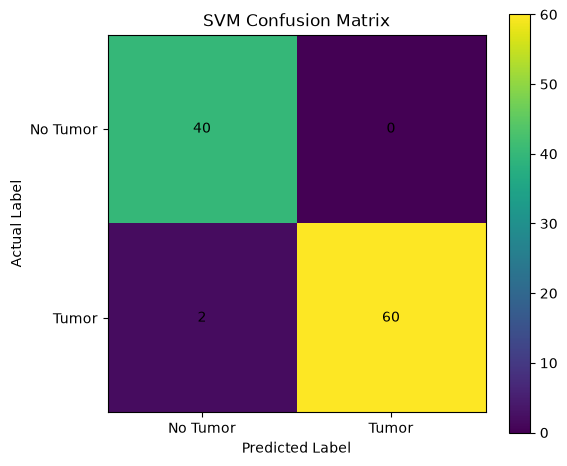

In [12]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["No Tumor", "Tumor"])
plt.yticks([0, 1], ["No Tumor", "Tumor"])
plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

## Sample Test Predictions

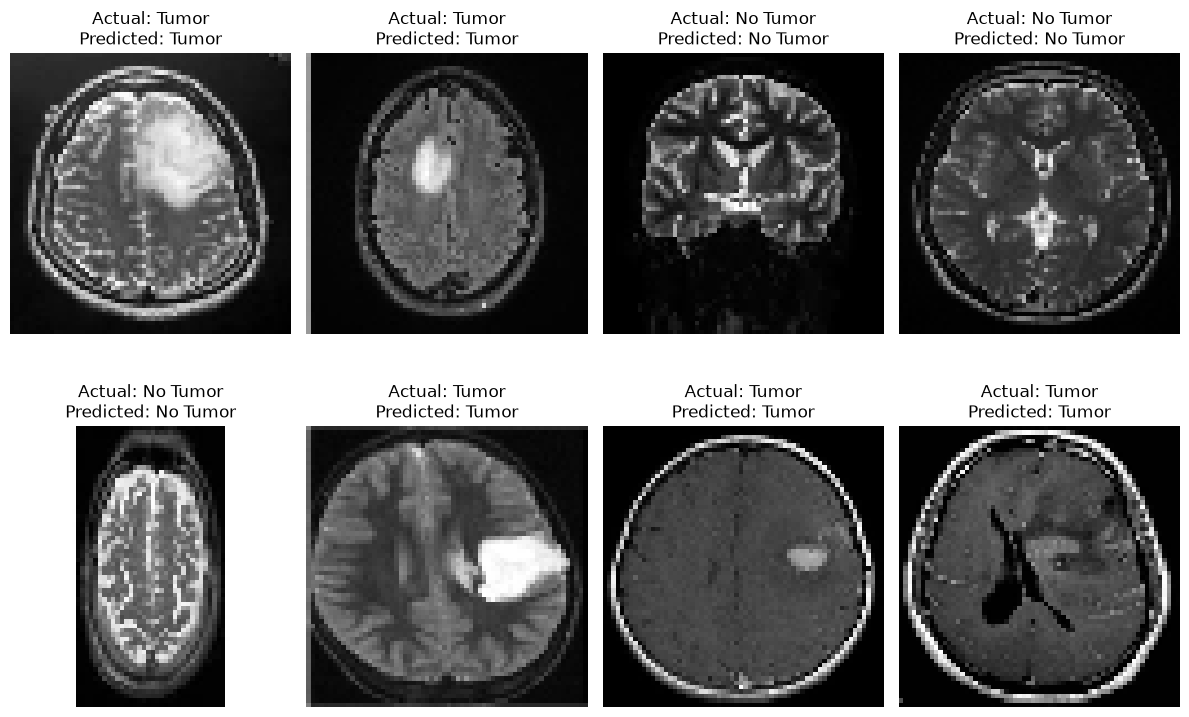

In [13]:
plt.figure(figsize=(12, 8))

num_images = min(8, len(images_test))

for i in range(num_images):
    plt.subplot(2, 4, i + 1)

    plt.imshow(images_test[i], cmap="gray")

    actual = "Tumor" if y_test[i] == 1 else "No Tumor"
    predicted = "Tumor" if y_pred[i] == 1 else "No Tumor"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()